# Step 5 — Drawing the game

Everything so far has been numbers. This notebook draws the game, and the reason is not
decoration: **contraction is very hard to believe from a table of numbers and obvious the
moment you see it.**

There is one design decision here that matters more than all the drawing code.

When a player dies, you could re-space the survivors evenly around the circle. It would
look tidy. It would also make contraction **invisible** — the picture would always be a
neat circle and you would never see the new edge appear.

So instead: **every player keeps the angle they started at, forever.** Dead players stay
where they are, drawn struck through. That leaves gaps, and the edge created by
contraction visibly jumps across the gap. It is drawn dashed, so you can tell a
contracted edge from an original one.

The one mechanism that makes this game interesting becomes the most obvious thing on
screen.

In [1]:
N = 6
SEED = 0

import numpy as np
import matplotlib.pyplot as plt

SHOOT_LEFT = 0
SHOOT_RIGHT = 1
MISS = 2

## 5.1 The game, once more

In [2]:
class Gruel:
    def __init__(self, n=3, seating="random", seed=0):
        self.n = n
        self.seating = seating
        self.rng = np.random.default_rng(seed)
        self.stagnation_rounds = 10
        self.max_steps = 200 * n

    def reset(self):
        accuracies_ascending = []
        for k in range(self.n):
            fraction = k / (self.n - 1)
            accuracies_ascending.append(0.4 + (0.8 - 0.4) * fraction)
        accuracies_ascending = np.array(accuracies_ascending)

        if self.seating == "ranked":
            self.accuracies = accuracies_ascending.copy()
        else:
            self.accuracies = self.rng.permutation(accuracies_ascending)

        self.order = list(range(self.n))
        self.t = 0
        self.miss_streak = 0
        self.finished = False
        self.reason = None
        self.rewards = np.zeros(self.n)
        self.actor = int(self.rng.choice(self.order))

    def n_alive(self):
        return len(self.order)

    def neighbours(self, position):
        index_in_order = self.order.index(position)
        how_many_alive = len(self.order)
        left = self.order[(index_in_order - 1) % how_many_alive]
        right = self.order[(index_in_order + 1) % how_many_alive]
        return left, right

    def observe(self, position):
        left, right = self.neighbours(position)
        return np.array([
            self.accuracies[position],
            self.accuracies[left],
            self.accuracies[right],
            self.n_alive() / self.n,
        ])

    def live_edges(self):
        """The pairs who can currently shoot each other."""
        edges = []
        how_many_alive = len(self.order)
        if how_many_alive < 2:
            return edges
        for index_in_order in range(how_many_alive):
            this_player = self.order[index_in_order]
            next_player = self.order[(index_in_order + 1) % how_many_alive]
            edges.append((this_player, next_player))
            if how_many_alive == 2:
                # With two left there is one edge, not two.
                break
        return edges

    def step(self, action):
        shooter = self.actor
        self.t = self.t + 1

        target = None
        victim = None
        hit = False

        if action == MISS:
            self.miss_streak = self.miss_streak + 1
        else:
            target = self.target_of(shooter, action)
            self.miss_streak = 0
            roll = self.rng.random()
            hit = roll < self.accuracies[shooter]
            if hit:
                victim = target

        if victim is not None:
            self.order.remove(victim)

        if self.n_alive() == 1:
            self.finished = True
            self.reason = "sole_survivor"
            self.rewards[self.order[0]] = 1.0
        elif self.miss_streak >= self.stagnation_rounds * self.n_alive():
            self.finished = True
            self.reason = "stagnation"
            share = 1.0 / self.n_alive()
            for position in self.order:
                self.rewards[position] = share
        elif self.t >= self.max_steps:
            self.finished = True
            self.reason = "hard_cap"

        if not self.finished:
            self.actor = int(self.rng.choice(self.order))

        return {"shooter": shooter, "action": action, "target": target,
                "hit": hit, "victim": victim}

    def target_of(self, position, action):
        if action == MISS:
            return None
        left, right = self.neighbours(position)
        if action == SHOOT_LEFT:
            return left
        else:
            return right


def shoot_strongest(observation, rng):
    if observation[1] > observation[2]:
        return SHOOT_LEFT
    else:
        return SHOOT_RIGHT

## 5.2 Where each player sits on the screen

Positions go around a circle, position 0 at the top, then clockwise.

The angle for position $i$ out of $n$ is

$$\theta_i = \frac{\pi}{2} - \frac{2\pi i}{n}$$

Two details. The $\pi/2$ starts us at the top rather than the right, because matplotlib
measures angles from the positive x-axis. **Subtracting** rather than adding makes it go
clockwise, since matplotlib's y-axis points up and angles otherwise increase
anticlockwise.

These angles are computed **once**, from the original `n`, and never recomputed — that is
the whole trick.

In [3]:
def node_positions(n):
    """Screen coordinates for every position. Fixed for the whole episode."""
    coordinates = []
    for i in range(n):
        angle = np.pi / 2 - 2 * np.pi * i / n
        x = np.cos(angle)
        y = np.sin(angle)
        coordinates.append((x, y))
    return coordinates


LAYOUT = node_positions(N)

for i in range(N):
    x, y = LAYOUT[i]
    print(f"position {i}: x={x:+.3f}, y={y:+.3f}")

position 0: x=+0.000, y=+1.000
position 1: x=+0.866, y=+0.500
position 2: x=+0.866, y=-0.500
position 3: x=+0.000, y=-1.000
position 4: x=-0.866, y=-0.500
position 5: x=-0.866, y=+0.500


## 5.3 Drawing one frame

Three kinds of line, and they must be told apart at a glance:

| Mark | Meaning |
|---|---|
| Solid pale line | An original edge — these two started as neighbours |
| **Dashed** coloured line | A **contracted** edge — these two only became neighbours because someone died |
| Arrow | A shot that was just fired |

Dead players are drawn faded with a line through them, and stay in place.

In [4]:
def draw_frame(axes, game, original_edges, event=None, caption=""):
    axes.clear()
    axes.set_xlim(-1.45, 1.45)
    axes.set_ylim(-1.45, 1.45)
    axes.set_aspect("equal")
    axes.axis("off")

    current_edges = game.live_edges()

    for edge in current_edges:
        first, second = edge
        x1, y1 = LAYOUT[first]
        x2, y2 = LAYOUT[second]

        # Was this pair adjacent at the start? If not, contraction created it.
        was_original = (first, second) in original_edges or (second, first) in original_edges

        if was_original:
            axes.plot([x1, x2], [y1, y2], color="0.80", linewidth=1.5, zorder=1)
        else:
            axes.plot([x1, x2], [y1, y2], color="tab:orange", linewidth=2.0,
                      linestyle="--", zorder=2)

    # The shot, if there was one.
    if event is not None and event["target"] is not None:
        shooter = event["shooter"]
        target = event["target"]
        x1, y1 = LAYOUT[shooter]
        x2, y2 = LAYOUT[target]

        if event["hit"]:
            arrow_colour = "tab:red"
        else:
            arrow_colour = "0.35"

        axes.annotate("", xy=(x2 * 0.82, y2 * 0.82), xytext=(x1 * 0.82, y1 * 0.82),
                      arrowprops=dict(arrowstyle="-|>", color=arrow_colour,
                                      linewidth=2.2, shrinkA=14, shrinkB=14),
                      zorder=4)

    # The players.
    for position in range(game.n):
        x, y = LAYOUT[position]
        alive = position in game.order
        accuracy = game.accuracies[position]

        if alive:
            face_colour = "white"
            edge_colour = "black"
            text_colour = "black"
        else:
            face_colour = "0.92"
            edge_colour = "0.70"
            text_colour = "0.60"

        # Highlight whoever is about to act.
        if alive and position == game.actor and not game.finished:
            edge_colour = "tab:blue"

        axes.scatter([x], [y], s=1500, facecolor=face_colour,
                     edgecolor=edge_colour, linewidth=2.5, zorder=5)
        # Two decimals, not one: at N=6 the accuracies 0.56 and 0.64 both round to "0.6"
        # and the picture then shows two players who look identical but are not.
        axes.text(x, y, f"p{position}\n{accuracy:.2f}", ha="center", va="center",
                  fontsize=8, color=text_colour, zorder=6)

        if not alive:
            # Strike through, so a dead player is visibly still in its seat.
            axes.plot([x - 0.13, x + 0.13], [y, y], color="tab:red",
                      linewidth=2.0, zorder=7)

    axes.set_title(caption, fontsize=9)

## 5.4 An episode, frame by frame

Watch the dashed orange lines appear. Every one of them is a pair of players who could not
reach each other at the start of the episode.

In [5]:
game = Gruel(n=N, seating="random", seed=SEED)
game.reset()

# Remember the starting edges so we can tell later which ones are new.
original_edges = set(game.live_edges())
print("original edges:", sorted(original_edges))

frames = []
frames.append(("start", None, list(game.order), game.actor))

while not game.finished:
    position = game.actor
    observation = game.observe(position)
    action = shoot_strongest(observation, game.rng)
    event = game.step(action)
    frames.append((f"t={game.t}", event, list(game.order), game.actor))

print("frames to draw:", len(frames))
print("ended because:", game.reason)
print("winner accuracy:", game.accuracies[game.order[0]])

original edges: [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)]
frames to draw: 13
ended because: sole_survivor
winner accuracy: 0.7200000000000001


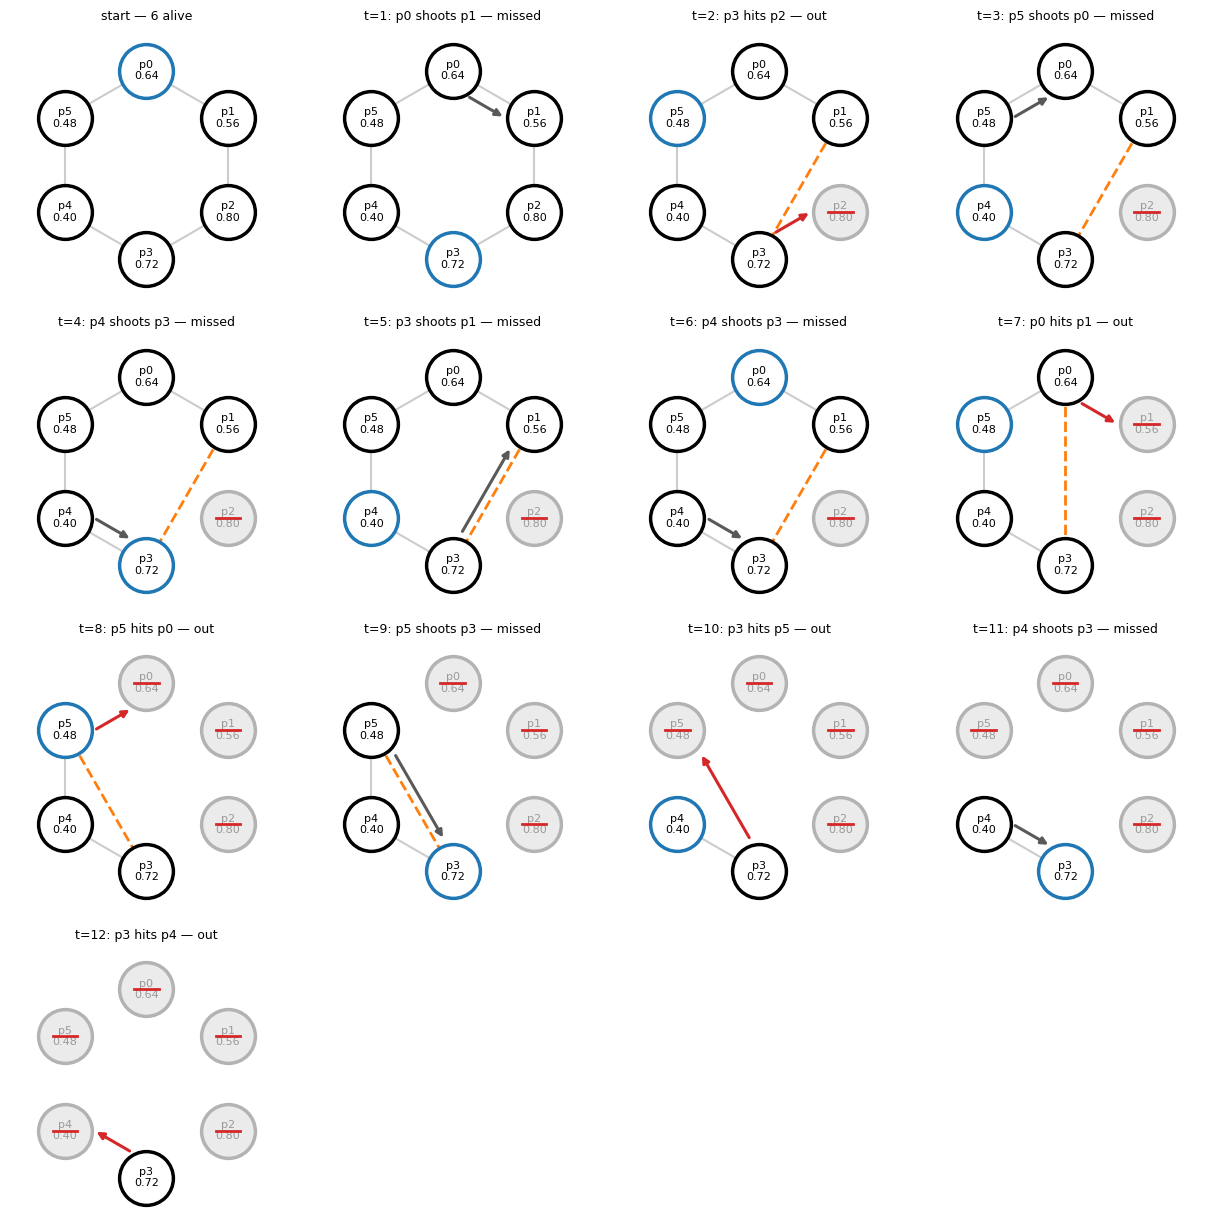

In [6]:
# Redraw the whole episode. We replay it with the same seed so the state matches each frame.
replay = Gruel(n=N, seating="random", seed=SEED)
replay.reset()

how_many = len(frames)
columns = 4
rows = int(np.ceil(how_many / columns))

figure, axes_grid = plt.subplots(rows, columns, figsize=(3.1 * columns, 3.1 * rows))
axes_flat = np.array(axes_grid).reshape(-1)

caption = f"start — {replay.n_alive()} alive"
draw_frame(axes_flat[0], replay, original_edges, None, caption)

frame_index = 1
while not replay.finished and frame_index < how_many:
    position = replay.actor
    observation = replay.observe(position)
    action = shoot_strongest(observation, replay.rng)
    event = replay.step(action)

    shooter = event["shooter"]
    if event["target"] is None:
        caption = f"t={replay.t}: p{shooter} abstains"
    elif event["hit"]:
        caption = f"t={replay.t}: p{shooter} hits p{event['target']} — out"
    else:
        caption = f"t={replay.t}: p{shooter} shoots p{event['target']} — missed"

    draw_frame(axes_flat[frame_index], replay, original_edges, event, caption)
    frame_index = frame_index + 1

# Blank out any unused panels.
for spare in range(frame_index, len(axes_flat)):
    axes_flat[spare].axis("off")

plt.tight_layout()
plt.show()

## 5.5 Before and after one death, side by side

The grid above has a lot going on. Here is the single clearest picture: the same circle
before and after one player is removed.

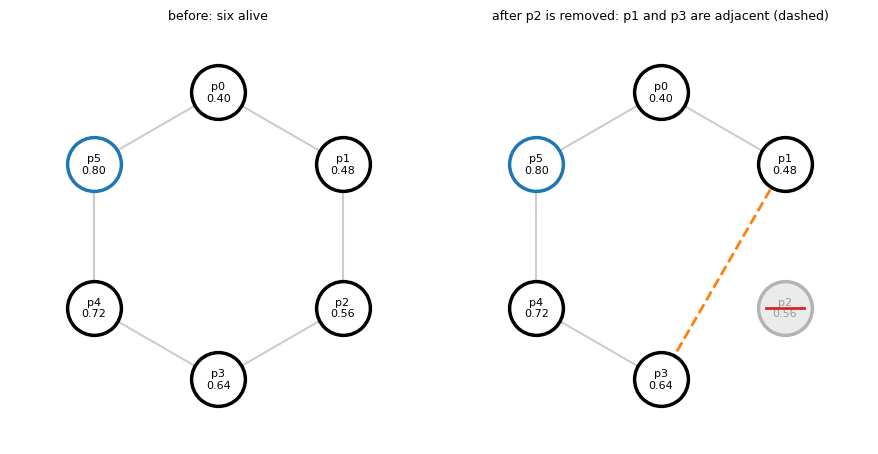

p1's neighbours now: (0, 3)
p3's neighbours now: (1, 4)

p1 and p3 could not shoot each other before. Now they can.


In [7]:
before = Gruel(n=6, seating="ranked", seed=SEED)
before.reset()
starting_edges = set(before.live_edges())

figure, axes_pair = plt.subplots(1, 2, figsize=(9, 4.5))

draw_frame(axes_pair[0], before, starting_edges, None, "before: six alive")

# Kill position 2 by hand so the picture is deterministic.
before.order.remove(2)
draw_frame(axes_pair[1], before, starting_edges, None,
           "after p2 is removed: p1 and p3 are adjacent (dashed)")

plt.tight_layout()
plt.show()

print("p1's neighbours now:", before.neighbours(1))
print("p3's neighbours now:", before.neighbours(3))
print()
print("p1 and p3 could not shoot each other before. Now they can.")

## 5.6 Does it stay readable at N=15?

The project needs to run at N=15, and a picture that turns into spaghetti is no use. Worth
checking rather than assuming.

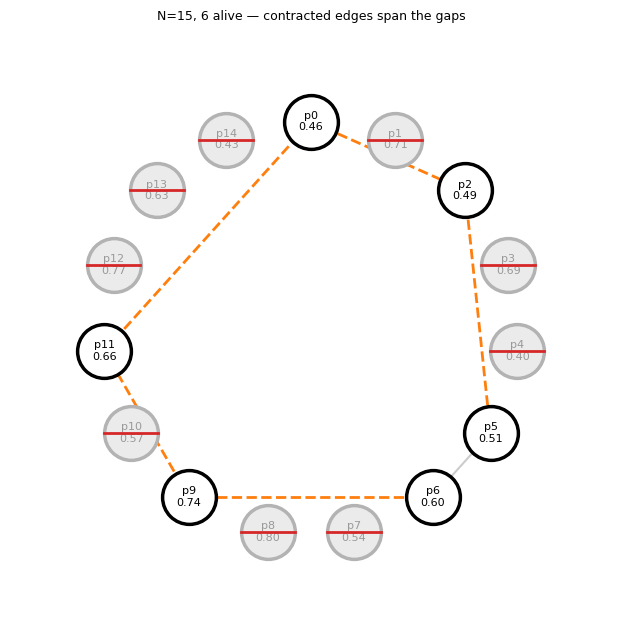

alive: [0, 2, 5, 6, 9, 11]
edges now: [(0, 2), (2, 5), (5, 6), (6, 9), (9, 11), (11, 0)]

Every dashed edge is a pair that only became adjacent through contraction.


In [8]:
LAYOUT = node_positions(15)

big = Gruel(n=15, seating="random", seed=SEED)
big.reset()
big_original = set(big.live_edges())

# Kill players until 6 remain, so there are plenty of contracted edges to look at.
victims = [1, 3, 4, 7, 8, 10, 12, 13, 14]
for victim in victims:
    big.order.remove(victim)

figure, axes = plt.subplots(figsize=(6.5, 6.5))
draw_frame(axes, big, big_original, None, "N=15, 6 alive — contracted edges span the gaps")
plt.tight_layout()
plt.show()

print("alive:", big.order)
print("edges now:", big.live_edges())
print()
print("Every dashed edge is a pair that only became adjacent through contraction.")

## 5.7 The live window

Matplotlib is fine for still frames, but watching an episode play out in real time needs
a proper window, and a window cannot live inside a notebook. That is what `play.py` is
for — a normal Python script using **pygame**, which is the same library Gymnasium's
CartPole uses.

```bash
./.venv/bin/python play.py --n 6 --fps 2
./.venv/bin/python play.py --n 15 --policy shoot_strongest
./.venv/bin/python play.py --n 5 --step        # SPACE to advance, Q to quit
```

`--step` is the useful one. It pauses on every frame so you can actually follow a
contraction instead of watching it flash past.

## 5.8 The seeding check

Same seed must give the same episode, including the same drawing.

In [9]:
def episode_fingerprint(seed):
    game = Gruel(n=N, seating="random", seed=seed)
    game.reset()
    steps = []
    while not game.finished:
        observation = game.observe(game.actor)
        action = shoot_strongest(observation, game.rng)
        event = game.step(action)
        steps.append((event["shooter"], event["action"], event["hit"]))
    return steps


first = episode_fingerprint(SEED)
second = episode_fingerprint(SEED)
different = episode_fingerprint(SEED + 1)

print("steps in seed-0 episode:", len(first))
print("steps in seed-1 episode:", len(different))
print()
print("same seed gives an identical episode:", first == second)

steps in seed-0 episode: 12
steps in seed-1 episode: 9

same seed gives an identical episode: True


## What to take from step 5

- Node angles are computed **once** and never recomputed. Re-spacing survivors would make
  contraction invisible, which is the one thing the picture exists to show.
- Dead players stay in their seats, struck through, leaving the gap that a contracted edge
  has to jump across.
- Contracted edges are drawn **dashed** so they are distinguishable from original ones.
- It stays readable at N=15, so no player-count limit is needed for this project.
- Live animation belongs in a script (`play.py`), not a notebook.

That completes deliverable 01. The game works, it is verified against the exact answer, it
has baselines to compare against, and you can watch it.

Next: folder `02-exact-solver`, which stops guessing and computes 8/27, 9/27 and 10/27
properly.